In [1]:
!git clone -q https://github.com/esa/SpOC2.git
%cd "/kaggle/working/SpOC2/Morphing Rovers"
!mkdir -p data/spoc2/morphing && cp -r data/Maps data/coordinates.txt data/example_rover.npy data/spoc2/morphing/
!sed -i "77s/.*/HEIGHTMAP_NAMES = ['Map1.jpg', 'Map2.jpg', 'Map3.jpg', 'Map4.jpg', 'Map5.jpg', 'Map6.jpg']/" morphing_udp.py
!sed -i '683s/, angle,/, float(angle),/' morphing_udp.py

/kaggle/working/SpOC2/Morphing Rovers


In [2]:
import numpy as np, time
import matplotlib.pyplot as plt
from morphing_udp import morphing_rover_UDP

udp = morphing_rover_UDP()
lb, ub = udp.get_bounds()
lb, ub = np.array(lb), np.array(ub)
print("Sa numra:", len(lb))
print("Kufiri min dhe max:", lb.min(), ub.max())

Sa numra: 19133
Kufiri min dhe max: -100.0 100


In [5]:
rng = np.random.default_rng(42)

def rover_i_rastesishem():
    x = rng.uniform(lb, ub)
    x[-7:] = np.round(x[-7:])   # 7 numrat e fundit duhet te jene te plote
    return x

In [6]:
N = 10   # sa rovera provojme
nota_me_e_mire = float("inf")
roveri_me_i_mire = None
historia = []

t = time.time()
for i in range(N):
    x = rover_i_rastesishem()
    nota = udp.fitness(x)[0]
    if nota < nota_me_e_mire:
        nota_me_e_mire = nota
        roveri_me_i_mire = x
    historia.append(nota_me_e_mire)
    print(f"Roveri {i+1}: nota {nota:.3f}   me e mira deri tash: {nota_me_e_mire:.3f}")
print("Koha:", round(time.time() - t), "sekonda")

Roveri 1: nota 10.279   me e mira deri tash: 10.279
Roveri 2: nota 10.195   me e mira deri tash: 10.195
Roveri 3: nota 9.919   me e mira deri tash: 9.919
Roveri 4: nota 9.970   me e mira deri tash: 9.919
Roveri 5: nota 10.087   me e mira deri tash: 9.919
Roveri 6: nota 9.992   me e mira deri tash: 9.919
Roveri 7: nota 7.488   me e mira deri tash: 7.488
Roveri 8: nota 8.478   me e mira deri tash: 7.488
Roveri 9: nota 10.032   me e mira deri tash: 7.488
Roveri 10: nota 10.087   me e mira deri tash: 7.488
Koha: 312 sekonda


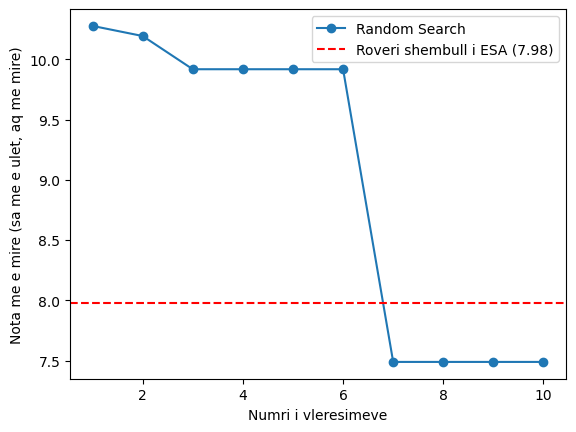

In [7]:
plt.plot(range(1, N+1), historia, marker="o", label="Random Search")
plt.axhline(7.98, color="red", linestyle="--", label="Roveri shembull i ESA (7.98)")
plt.xlabel("Numri i vleresimeve")
plt.ylabel("Nota me e mire (sa me e ulet, aq me mire)")
plt.legend()
plt.show()
np.save("random_search_best.npy", roveri_me_i_mire)